# Rossmann Store Sales Forecasting
**NextHikes IT Solutions | Machine Learning Engineering Project**

---

# Section 1: Project Overview, Objectives and Success Criteria

**Purpose of this section:** Define exactly what the system will predict, for whom, using what information, and how we will judge whether it works. Every requirement in the project brief is mapped to a section and a deliverable, and three project registers (Decision Register, Evaluation-Access Log, Limitations List) are started here and kept up to date throughout.

## 1.1 Business Problem

Rossmann Pharmaceuticals operates over a thousand stores across several cities. The finance team needs to know how much each store will sell **six weeks ahead** so that staffing, stock and budgets can be planned in advance. At present, store managers forecast using years of experience and personal judgement, which is hard to audit, compare across stores or scale.

The data team has identified promotions, competition, school and state holidays, seasonality and store characteristics as the main factors that influence sales. This project turns those factors into an end-to-end product:

1. an analysis of customer purchasing behaviour,
2. a tested forecasting model (machine learning and deep learning),
3. a web application where finance analysts and store managers can request forecasts and download them.

## 1.2 Objectives

1. Explore and clean the sales, customer and store data, and answer the purchasing-behaviour questions in the brief.
2. Build, validate and compare forecasting models (a seasonal and average baseline, machine learning pipelines and a two-layer LSTM) using a validation design that mirrors the real forecasting task.
3. Forecast **Sales** and **Customers** per store per day, with an estimate of the uncertainty around each forecast.
4. Explain what drives the forecasts in language a finance analyst can use.
5. Package the models with timestamped versions, track data and model versions (DVC and MLflow), and serve forecasts in a hosted web application.
6. Document the project so that someone else can understand, reproduce and use it.

## 1.3 Prediction Targets

| Target | Role | Notes |
|---|---|---|
| **Sales** | Primary target | Daily turnover per store. Closed days have zero sales. |
| **Customers** | Secondary target | Requested by the dashboard instructions. `Customers` is not in `test.csv`, so it cannot be an input to the sales model and needs its own model. |

## 1.4 Forecast Horizon

- **Main forecasting horizon:** 42 days (six weeks), from a fixed forecast origin.
- **Supplied test set:** 48 days of dates immediately after the training period. The same pipeline must produce forecasts for all 48 days and all 856 test stores.
- **Final export:** one prediction for every row of `test.csv`, matched through `Id`.

## 1.5 Intended Users and Decisions Supported

| User | Decision supported |
|---|---|
| Finance analysts | Six-week revenue planning, budgeting, spotting stores where forecasts and plans diverge |
| Store managers | Staffing, stock ordering and promotion timing for their store |

## 1.6 Information Available at Prediction Time

A forecast is only valid if it uses information that would actually be known on the day the forecast is made.

| Information | Available at forecast time? | Use |
|---|---|---|
| Calendar and date features | Yes | Always allowed |
| Store metadata (type, assortment, competition, Promo2 details) | Yes | Always allowed |
| Scheduled promotions and holidays | Yes, if supplied or planned | Allowed |
| Future opening status | Only as supplied in the opening plans | Allowed; missing values need a documented assumption |
| Historical sales and customers | Only **before** the forecast origin | Allowed for origin-based features |
| Actual customers on a future day | No | Excluded from all sales inputs |
| Actual sales inside the forecast window | No | Never used to build forecast features |

## 1.7 Success Criteria

The project is successful if all of the following hold:

1. **Accuracy.** The selected model beats every baseline on each rolling validation window and on the final 42-day holdout, using RMSPE on positive-sales days as the primary metric (MAE and RMSE as secondary metrics). A numeric target is fixed after the baselines are measured (Section 7) and recorded in the Decision Register.
2. **Fairness across stores and time.** No store type, forecast week or holiday group has a markedly worse error without an explanation.
3. **Honest uncertainty.** Nominal 90% prediction intervals reach empirical coverage close to 90% (proposed tolerance: about ±5 percentage points) on calibration data kept separate from the final holdout.
4. **Validity.** Leakage checks pass, closed days are predicted as zero and all predictions are finite and non-negative.
5. **Deep learning.** The LSTM is built correctly, is reproducible and is compared fairly with the machine learning finalist. It does not have to win.
6. **Delivery and consistency.** A hosted app works end to end, DVC and MLflow show multiple versions, and every reported number matches the saved results across notebook, report and app.

## 1.8 Scope and Limits

**In scope:** daily store-level forecasts of Sales and Customers, based on the supplied files.

**Out of scope or not supported by the data:**
- Causal claims about promotions (associations only).
- Hourly behaviour (the data is daily).
- Returning-customer analysis (only daily customer counts exist).
- City-centre effects (there is no location information).
- Changes in competitor distance over time (`store.csv` is a static snapshot).

These are tracked in the Limitations List in Section 1.10.

## 1.9 Requirements Checklist

Every requirement in the brief is assigned to a section and a deliverable. **Phase** shows whether it belongs to the interim or final submission. Status is updated as the project progresses.

| ID | Requirement from the brief | Section | Deliverable / evidence | Phase | Status |
|---|---|---|---|---|---|
| R01 | Clean data with pipelines that detect and handle outliers and missing data | 3 | Data-quality table, DVC cleaned-data version | Interim | Pending |
| R02 | Log steps with the Python `logging` library | 2 (used throughout) | `src/logger.py`, `logs/` | Interim | Pending |
| R03 | Q1: Are promotions distributed similarly in train and test? | 5 | Plot and table | Interim | Pending |
| R04 | Q2: Sales before, during and after holidays | 5 | Plots | Interim | Pending |
| R05 | Q3: Seasonal behaviour (Christmas, Easter, etc.) | 5 | Plots | Interim | Pending |
| R06 | Q4: Correlation between sales and customers | 5 | Plot and statistics | Interim | Pending |
| R07 | Q5: Effect of promos on sales, customers and existing customers | 5 | Plots and table | Interim | Pending |
| R08 | Q6: Where promos could be deployed more effectively, and in which stores | 5 | Ranked table | Interim | Pending |
| R09 | Q7: Customer behaviour around opening and closing (daily open/closed only) | 5 | Plot, limitation noted | Interim | Pending |
| R10 | Q8: Stores open on all weekdays and their weekend sales | 5 | Plot and table | Interim | Pending |
| R11 | Q9: Effect of assortment type on sales | 5 | Plot | Interim | Pending |
| R12 | Q10: Effect of competitor distance (city-centre check) | 5 | Plot, limitation noted | Interim | Pending |
| R13 | Q11: Effect of competitor opening, and NA-to-known distance (partly answerable) | 5 | Plot, limitation noted | Interim | Pending |
| R14 | Additional questions of my own (for an excellent analysis) | 5 | Extra plots and insights | Interim | Pending |
| R15 | 3-5 slide presentation of exploration findings | 5 | Slide deck | Interim | Pending |
| R16 | Convert non-numeric columns, handle NaNs | 3, 6 | Cleaning and feature pipeline | Final | Pending |
| R17 | Date features: weekday, weekend, days to and after holidays, month start/mid/end (plus extras for bonus marks) | 6 | Feature table | Final | Pending |
| R18 | Scale the data with `StandardScaler` | 6 | Pipeline step | Final | Pending |
| R19 | Build models with sklearn pipelines (extra marks) | 6, 7 | Pipeline code | Final | Pending |
| R20 | Tree-based starting model (Random Forest Regressor) | 7 | Model comparison table | Final | Pending |
| R21 | Choose and defend a loss function | 6 (decision), 7 (defence) | Written justification | Final | Pending |
| R22 | Feature importance | 9 | Importance plots | Final | Pending |
| R23 | Confidence interval estimate for predictions (extra marks) | 9 | Interval plots, coverage table | Final | Pending |
| R24 | Serialize models with a timestamp (e.g. `dd-mm-yyyy-HH-MM-SS.pkl`) | 10 | `models/` folder | Final | Pending |
| R25 | LSTM: time series, stationarity, differencing, ACF/PACF, sliding window, (-1, 1) scaling, two layers, runs in Colab | 8 | LSTM notebook section, results table | Final | Pending |
| R26 | Use MLflow to serve predictions on test data | 10 (tracking set up in 2, 7) | MLflow inference demo | Final | Pending |
| R27 | Predicted customer numbers alongside sales | 9, 11 | Customer model, app output | Final | Pending |
| R28 | Web app inputs: Store ID, CSV upload (Date, IsHoliday, IsWeekend, IsPromo, others), other model inputs | 11 | Streamlit app | Final | Pending |
| R29 | App shows a plot of predictions and allows CSV download | 11 | App screenshots | Final | Pending |
| R30 | Host the app and submit the link | 11 | Deployed link | Final | Pending |
| R31 | Screenshots of multiple data versions in DVC | 2, 3, 6 (evidence in 12) | DVC screenshot | Interim | Pending |
| R32 | Screenshots of multiple model versions in MLflow | 7, 8 (evidence in 12) | MLflow screenshot | Interim | Pending |
| R33 | GitHub link including the Jupyter notebook | 12 | Repository | Interim and Final | Pending |
| R34 | Blog-style PDF with extra weight on deep learning | 12 | PDF | Final | Pending |
| R35 | Modular code (reusable functions in `src/`) | 2, 6, 10 | `src/` package | Final | Pending |
| R36 | Badge categories: visualisation, code quality, innovation, writing, community | All | Quality of the final package | Final | Pending |

**Completion condition for Section 1:** every requirement above has an assigned section and deliverable. All 36 rows do.

## 1.10 Project Registers

Three registers run through the whole project:

- **Decision Register:** every important choice, with its reason and status (provisional or confirmed).
- **Evaluation-Access Log:** a record of each time the final historical holdout is scored. The holdout must be used only once, after all choices are locked.
- **Limitations List:** what the data cannot support, added to as we inspect it.

The registers are created below with their starting entries and helper functions to add new rows. The same objects are used in later sections and saved to `outputs/` so the report can quote them.

In [1]:
import pandas as pd
from datetime import datetime
from pathlib import Path

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# ---------------------------------------------------------------------------
# Decision Register
# ---------------------------------------------------------------------------
DECISION_COLS = ["id", "section", "decision", "reason", "status"]

decision_register = pd.DataFrame(
    [
        ("D01", 1, "Primary target is Sales; Customers is a secondary target with its own model.",
         "Dashboard needs both outputs; Customers is not in test.csv, so it cannot feed the sales model.",
         "Confirmed"),
        ("D02", 1, "Main forecast horizon is 42 days; the same pipeline covers the 48-day test window.",
         "Brief asks for six weeks ahead; test.csv spans 48 days.",
         "Confirmed"),
        ("D03", 1, "Final holdout = last 42 labelled days of train, scored once after all choices are locked.",
         "Gives an honest estimate of forecast error; test.csv has no Sales to score against.",
         "Provisional (exact dates fixed in Section 4)"),
        ("D04", 1, "Three earlier rolling 42-day validation windows with common cut-offs across stores.",
         "Tests stability across time without touching the final holdout.",
         "Provisional (fixed in Section 4)"),
        ("D05", 1, "Model log1p(Sales); loss = RMSE on the log scale; primary metric = RMSPE on positive-sales days; MAE and RMSE secondary.",
         "Sales is right-skewed and finance cares about percentage error; log RMSE behaves like relative error.",
         "Provisional (defended in Section 7)"),
        ("D06", 1, "Predict zero when a store is closed; train on open days only.",
         "All closed days have zero sales; including them would distort the model.",
         "Confirmed (verified in the data audit)"),
        ("D07", 1, "Do not cap Sales with IQR rules; treat outliers only with evidence from store histories.",
         "High sales may be genuine holiday or promotion peaks the model must learn.",
         "Confirmed"),
        ("D08", 1, "No actual future Customers or Sales may be used as forecast inputs; history is allowed only before the forecast origin.",
         "Prevents leakage; Customers is not available in test.csv.",
         "Confirmed"),
        ("D09", 1, "Use a shared LSTM across stores (store and calendar inputs) as the main deep learning design.",
         "More practical than 1,115 separate models and runs in Colab.",
         "Provisional (confirmed in Section 8)"),
        ("D10", 1, "Build the app with Streamlit and host it on a free platform.",
         "Brief allows Streamlit; free hosting is sufficient for the project.",
         "Provisional (confirmed in Section 11)"),
        ("D11", 1, "Unit tests, CI/CD and Docker are optional; list as pending if skipped.",
         "Not required by the brief; avoid claiming work that was not done.",
         "Confirmed"),
    ],
    columns=DECISION_COLS,
)

# ---------------------------------------------------------------------------
# Evaluation-Access Log (starts empty; the final holdout must be logged here)
# ---------------------------------------------------------------------------
EVAL_COLS = ["timestamp", "section", "dataset", "model", "purpose", "result_summary"]
evaluation_log = pd.DataFrame(columns=EVAL_COLS)

# ---------------------------------------------------------------------------
# Limitations List
# ---------------------------------------------------------------------------
LIMIT_COLS = ["id", "section", "limitation", "effect_on_conclusions"]

limitations = pd.DataFrame(
    [
        ("L01", 1, "The data is daily; there is no hourly or opening-time information.",
         "Opening and closing behaviour can only be studied as open vs closed days."),
        ("L02", 1, "Promotion effects are observed associations, not controlled experiments.",
         "No causal uplift can be claimed; Promo2 stores selling less may reflect who is targeted."),
        ("L03", 1, "Only daily customer counts exist.",
         "Returning vs new customers cannot be identified."),
        ("L04", 1, "There is no location information (no city or city-centre flag).",
         "The city-centre part of the competitor-distance question cannot be tested."),
        ("L05", 1, "store.csv is a static snapshot.",
         "Changes from missing to known competitor distance over time cannot be observed."),
        ("L06", 1, "test.csv has no Sales or Customers.",
         "Accuracy can only be measured on labelled history, not on the supplied test period."),
        ("L07", 1, "180 stores are missing the same six-month block in one year.",
         "Needs flagging; rolling and sequence features must not cross the gap."),
        ("L08", 1, "School holidays are far more common in test (44%) than in train (18%); state holidays b and c never occur in test.",
         "Train/test shift: performance on those patterns cannot be confirmed from the test period."),
    ],
    columns=LIMIT_COLS,
)

# ---------------------------------------------------------------------------
# Helper functions used by later sections
# ---------------------------------------------------------------------------
def log_decision(section, decision, reason, status="Confirmed"):
    """Append a decision to the Decision Register and return its id."""
    global decision_register
    new_id = f"D{len(decision_register) + 1:02d}"
    decision_register.loc[len(decision_register)] = [new_id, section, decision, reason, status]
    return new_id

def log_limitation(section, limitation, effect_on_conclusions):
    """Append a limitation to the Limitations List and return its id."""
    global limitations
    new_id = f"L{len(limitations) + 1:02d}"
    limitations.loc[len(limitations)] = [new_id, section, limitation, effect_on_conclusions]
    return new_id

def log_evaluation(section, dataset, model, purpose, result_summary):
    """Record every scoring of the FINAL holdout (and other key evaluations)."""
    global evaluation_log
    evaluation_log.loc[len(evaluation_log)] = [
        datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        section, dataset, model, purpose, result_summary,
    ]

def save_registers():
    """Save all three registers to outputs/ so the report and app can quote them."""
    decision_register.to_csv(OUTPUT_DIR / "decision_register.csv", index=False)
    evaluation_log.to_csv(OUTPUT_DIR / "evaluation_log.csv", index=False)
    limitations.to_csv(OUTPUT_DIR / "limitations.csv", index=False)

save_registers()

print("Decision Register")
display(decision_register)
print("\nLimitations List")
display(limitations)
print("\nEvaluation-Access Log (empty until the final holdout is scored)")
display(evaluation_log)

Decision Register


,id,section,decision,reason,status
0,D01,1,Primary target is Sales; Customers is a secondary target with its own model.,"Dashboard needs both outputs; Customers is not in test.csv, so it cannot feed the sales model.",Confirmed
1,D02,1,Main forecast horizon is 42 days; the same pipeline covers the 48-day test window.,Brief asks for six weeks ahead; test.csv spans 48 days.,Confirmed
2,D03,1,"Final holdout = last 42 labelled days of train, scored once after all choices are locked.",Gives an honest estimate of forecast error; test.csv has no Sales to score against.,Provisional (exact dates fixed in Section 4)
3,D04,1,Three earlier rolling 42-day validation windows with common cut-offs across stores.,Tests stability across time without touching the final holdout.,Provisional (fixed in Section 4)
4,D05,1,Model log1p(Sales); loss = RMSE on the log scale; primary metric = RMSPE on positive-sales days; MAE and RMSE secondary.,Sales is right-skewed and finance cares about percentage error; log RMSE behaves like relative error.,Provisional (defended in Section 7)
5,D06,1,Predict zero when a store is closed; train on open days only.,All closed days have zero sales; including them would distort the model.,Confirmed (verified in the data audit)
6,D07,1,Do not cap Sales with IQR rules; treat outliers only with evidence from store histories.,High sales may be genuine holiday or promotion peaks the model must learn.,Confirmed
7,D08,1,No actual future Customers or Sales may be used as forecast inputs; history is allowed only before the forecast origin.,Prevents leakage; Customers is not available in test.csv.,Confirmed
8,D09,1,Use a shared LSTM across stores (store and calendar inputs) as the main deep learning design.,"More practical than 1,115 separate models and runs in Colab.",Provisional (confirmed in Section 8)
9,D10,1,Build the app with Streamlit and host it on a free platform.,Brief allows Streamlit; free hosting is sufficient for the project.,Provisional (confirmed in Section 11)



Limitations List


,id,section,limitation,effect_on_conclusions
0,L01,1,The data is daily; there is no hourly or opening-time information.,Opening and closing behaviour can only be studied as open vs closed days.
1,L02,1,"Promotion effects are observed associations, not controlled experiments.",No causal uplift can be claimed; Promo2 stores selling less may reflect who is targeted.
2,L03,1,Only daily customer counts exist.,Returning vs new customers cannot be identified.
3,L04,1,There is no location information (no city or city-centre flag).,The city-centre part of the competitor-distance question cannot be tested.
4,L05,1,store.csv is a static snapshot.,Changes from missing to known competitor distance over time cannot be observed.
5,L06,1,test.csv has no Sales or Customers.,"Accuracy can only be measured on labelled history, not on the supplied test period."
6,L07,1,180 stores are missing the same six-month block in one year.,Needs flagging; rolling and sequence features must not cross the gap.
7,L08,1,School holidays are far more common in test (44%) than in train (18%); state holidays b and c never occur in test.,Train/test shift: performance on those patterns cannot be confirmed from the test period.



Evaluation-Access Log (empty until the final holdout is scored)


,timestamp,section,dataset,model,purpose,result_summary


## 1.11 Section 1 Summary

**What is now fixed**
- We forecast **Sales** (primary) and **Customers** (secondary) per store per day, with a main horizon of **42 days** and a **48-day** supplied test window.
- Forecasts may only use information available at the forecast origin; actual future customers and sales are never inputs.
- Success is judged on accuracy against baselines, stability across stores and time, calibrated uncertainty intervals, leakage-free validity and consistent, reproducible delivery.
- All 36 requirements in the brief have an assigned section and deliverable.
- The Decision Register (11 entries), Limitations List (8 entries) and Evaluation-Access Log (empty) are started.

**What comes next**
- **Section 2** sets up the environment, logging, project structure, plotting style, DVC, MLflow and a minimal Streamlit app.

---

# Section 2: Setup, Reproducibility and Project Structure

**Purpose of this section:** Make the project rerunnable from a clean start and prepare deployment early. By the end, data loading, logging, data and experiment tracking and a basic web app all work.

| Step | What it sets up |
|---|---|
| 2.1 | Install packages |
| 2.2 | Project folders and Git ignore rules |
| 2.3 | Central configuration, logging, helper functions and plotting style (`src/` package) |
| 2.4 | Seeds, package versions and requirements files |
| 2.5 | Colour palette check and figure/table numbering |
| 2.6 | Raw data check |
| 2.7 | Git and DVC (first data version) |
| 2.8 | MLflow trial experiment |
| 2.9 | Minimal Streamlit app and deployment check |
| 2.10 | Section checks, decisions and first commit |

## 2.1 Install Packages

The packages below cover data handling, modelling, tracking and the app. TensorFlow or PyTorch for the LSTM is installed later, in Section 8. If the notebook asks you to restart the runtime after installing, restart and continue from Cell 3.

In [2]:
%pip install -q pandas numpy scipy scikit-learn statsmodels matplotlib seaborn lightgbm shap mlflow dvc streamlit joblib

Note: you may need to restart the kernel to use updated packages.


## 2.2 Project Structure

The analysis lives in one master notebook. Reusable code (cleaning, features, training, prediction) goes into `src/` so that the notebook and the web app run exactly the same logic.

| Folder / file | Purpose |
|---|---|
| `notebooks/` | Master analysis notebook |
| `src/` | Reusable code: configuration, logging, plotting style, later cleaning, features, training and prediction |
| `data/raw`, `data/interim`, `data/processed` | Original, cleaned and feature-ready data, tracked with DVC |
| `models/` | Timestamped model files |
| `outputs/` | Metrics, registers, prediction exports and saved tables |
| `figures/` | Figures used in the report and presentation |
| `logs/` | Log files written by the Python logger |
| `tests/` | Checks for key processing behaviour (optional) |
| `app.py`, `.streamlit/` | Streamlit application and its theme |
| `README.md`, `requirements.txt`, `requirements-dev.txt` | Setup and reproduction instructions, app and full dependencies |

The cell below creates the folders, moves the notebook session to the project root (so every later path is relative to the same place) and writes the Git ignore rules and a README starter.

In [3]:
import os
import sys
from pathlib import Path

# Project root = current folder, or its parent if this notebook sits inside notebooks/
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

FOLDERS = [
    "notebooks", "src", "tests", ".streamlit",
    "data/raw", "data/interim", "data/processed",
    "models", "outputs", "figures", "logs",
]
for folder in FOLDERS:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

(ROOT / "src" / "__init__.py").touch()
(ROOT / "tests" / ".gitkeep").touch()

os.chdir(ROOT)                     # all later relative paths (and %%writefile) start here
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

gitignore = ROOT / ".gitignore"
if not gitignore.exists():
    gitignore.write_text(
        "# Python and notebook files\n__pycache__/\n*.pyc\n.ipynb_checkpoints/\n.venv/\n.DS_Store\n"
        "# Logs and experiment-tracking stores (not versioned in Git)\nlogs/\nmlruns/\nmlflow.db\n"
        "# Data is versioned with DVC; DVC adds its own ignore entries for tracked folders\n"
    )

readme = ROOT / "README.md"
if not readme.exists():
    readme.write_text(
        "# Rossmann Store Sales Forecasting\n\n"
        "Forecast daily sales and customers for Rossmann stores up to six weeks ahead, "
        "and serve the forecasts in a web app.\n\n"
        "## Setup\n1. `pip install -r requirements-dev.txt`\n"
        "2. Put train.csv, test.csv, store.csv and sample_submission.csv in `data/raw/`.\n"
        "3. Run the notebook in `notebooks/`.\n\n"
        "(Sections on reproduction, data and model retrieval and the app are completed in Section 12.)\n"
    )

print("Project root:", ROOT)
print(sorted(p.name for p in ROOT.iterdir()))

Project root: /Users/kyra/Downloads/project 6
['.DS_Store', '.gitignore', '.streamlit', 'Attempt 1.ipynb', 'README.md', 'Ration Card.pdf', 'data', 'figures', 'logs', 'models', 'notebooks', 'outputs', 'problem statement.pdf', 'rossmann-store-sales', 'src', 'tests']


## 2.3 Central Configuration, Logging and Plotting Style

Settings that several sections need (paths, seed, forecast horizon, tracking names) are defined once in `src/config.py`, so a change is made in one place. Three more small modules follow:

- `src/logger.py`: one logger used everywhere, writing to the screen and to `logs/project.log` (the logging requirement in the brief).
- `src/utils.py`: seeds, package versions and requirements files.
- `src/style.py`: the project colour palette, the shared plotting style and automatic figure and table numbering.

In [4]:
%%writefile src/config.py
"""Central project configuration. Import values from here instead of hard-coding them."""
from pathlib import Path

# ---------------------------------------------------------------- reproducibility
SEED = 42

# ---------------------------------------------------------------- paths
ROOT = Path(__file__).resolve().parents[1]          # project root = parent of src/
DATA_RAW = ROOT / "data" / "raw"
DATA_INTERIM = ROOT / "data" / "interim"
DATA_PROCESSED = ROOT / "data" / "processed"
MODELS_DIR = ROOT / "models"
OUTPUTS_DIR = ROOT / "outputs"
FIGURES_DIR = ROOT / "figures"
LOGS_DIR = ROOT / "logs"

RAW_FILES = {
    "train": DATA_RAW / "train.csv",
    "test": DATA_RAW / "test.csv",
    "store": DATA_RAW / "store.csv",
    "sample_submission": DATA_RAW / "sample_submission.csv",
}

# ---------------------------------------------------------------- forecasting design
TARGET_SALES = "Sales"
TARGET_CUSTOMERS = "Customers"
HORIZON_DAYS = 42            # main forecast horizon (six weeks)
TEST_DAYS = 48               # length of the supplied test window
N_ROLLING_WINDOWS = 3        # earlier 42-day validation windows before the final holdout
INTERVAL_LEVEL = 0.90        # nominal coverage of prediction intervals

# ---------------------------------------------------------------- tracking and model files
MLFLOW_TRACKING_URI = f"sqlite:///{(ROOT / 'mlflow.db').as_posix()}"
MLFLOW_EXPERIMENT = "rossmann-sales-forecasting"
MLFLOW_SETUP_EXPERIMENT = "setup-check"
MODEL_TIMESTAMP_FORMAT = "%d-%m-%Y-%H-%M-%S"   # e.g. 10-08-2026-16-32-31.pkl

Overwriting src/config.py


In [5]:
%%writefile src/logger.py
"""Project-wide logging: every module calls get_logger() and logs to console and logs/project.log."""
import logging
import sys

from .config import LOGS_DIR

_FORMAT = "%(asctime)s | %(levelname)-8s | %(name)s | %(message)s"


def get_logger(name: str = "rossmann", level: int = logging.INFO) -> logging.Logger:
    """Return a configured logger (handlers are added once, so re-running a cell never duplicates lines)."""
    LOGS_DIR.mkdir(parents=True, exist_ok=True)
    logger = logging.getLogger(name)
    if logger.handlers:
        return logger
    logger.setLevel(level)
    logger.propagate = False
    formatter = logging.Formatter(_FORMAT, datefmt="%Y-%m-%d %H:%M:%S")

    console = logging.StreamHandler(sys.stdout)
    console.setFormatter(formatter)
    logfile = logging.FileHandler(LOGS_DIR / "project.log", encoding="utf-8")
    logfile.setFormatter(formatter)

    logger.addHandler(console)
    logger.addHandler(logfile)
    return logger

Overwriting src/logger.py


In [6]:
%%writefile src/logger.py
"""Project-wide logging: every module calls get_logger() and logs to console and logs/project.log."""
import logging
import sys

from .config import LOGS_DIR

_FORMAT = "%(asctime)s | %(levelname)-8s | %(name)s | %(message)s"


def get_logger(name: str = "rossmann", level: int = logging.INFO) -> logging.Logger:
    """Return a configured logger (handlers are added once, so re-running a cell never duplicates lines)."""
    LOGS_DIR.mkdir(parents=True, exist_ok=True)
    logger = logging.getLogger(name)
    if logger.handlers:
        return logger
    logger.setLevel(level)
    logger.propagate = False
    formatter = logging.Formatter(_FORMAT, datefmt="%Y-%m-%d %H:%M:%S")

    console = logging.StreamHandler(sys.stdout)
    console.setFormatter(formatter)
    logfile = logging.FileHandler(LOGS_DIR / "project.log", encoding="utf-8")
    logfile.setFormatter(formatter)

    logger.addHandler(console)
    logger.addHandler(logfile)
    return logger

Overwriting src/logger.py


In [7]:
%%writefile src/style.py
"""Shared look for every figure, table, the Streamlit app and the slides (palette taken from the reference image)."""
import re

import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

from .config import FIGURES_DIR, OUTPUTS_DIR

# ---------------------------------------------------------------- palette
PALETTE = {
    "espresso":   "#37170C",   # titles, axis text, actual values
    "umber":      "#772F12",   # dark primary, table headers
    "charcoal":   "#584F43",   # secondary text, gridlines
    "clay":       "#845C36",   # secondary series
    "terracotta": "#C44F10",   # primary accent (promo, key bars)
    "rose":       "#DA4A53",   # alerts, errors, closed or negative
    "bronze":     "#BB7534",   # third series
    "stone":      "#8A897A",   # baselines, neutral, "other"
    "marigold":   "#EF920D",   # main sales / forecast line
    "saffron":    "#F0BA25",   # highlights, annotations
    "sand":       "#EEC288",   # fills, prediction-interval bands
    "cream":      "#F7F2DC",   # backgrounds
}

# at most 5 clearly different colours for comparing groups; keep the group-to-colour mapping fixed
CATEGORICAL = [PALETTE[k] for k in ("terracotta", "marigold", "clay", "stone", "rose")]

# fixed meaning for forecasting plots
FORECAST_COLORS = {
    "actual": PALETTE["espresso"],
    "forecast": PALETTE["marigold"],
    "interval": PALETTE["sand"],
    "baseline": PALETTE["stone"],
    "error": PALETTE["rose"],
}

# sequential scale (low to high intensity) and a diverging scale (negative to positive)
SEQ_CMAP = LinearSegmentedColormap.from_list(
    "rossmann_seq",
    [PALETTE[k] for k in ("cream", "sand", "marigold", "terracotta", "umber", "espresso")],
)
DIV_CMAP = LinearSegmentedColormap.from_list(
    "rossmann_div", [PALETTE["charcoal"], PALETTE["cream"], PALETTE["terracotta"]]
)


def apply_style() -> None:
    """Apply the shared matplotlib style (cream background, espresso text, light gridlines)."""
    mpl.rcParams.update({
        "figure.facecolor": PALETTE["cream"], "axes.facecolor": PALETTE["cream"],
        "savefig.facecolor": PALETTE["cream"],
        "axes.edgecolor": PALETTE["charcoal"], "axes.labelcolor": PALETTE["espresso"],
        "axes.titlecolor": PALETTE["espresso"], "text.color": PALETTE["espresso"],
        "xtick.color": PALETTE["charcoal"], "ytick.color": PALETTE["charcoal"],
        "axes.grid": True, "grid.color": PALETTE["charcoal"], "grid.alpha": 0.15,
        "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
        "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 11,
        "xtick.labelsize": 10, "ytick.labelsize": 10,
        "legend.frameon": False, "legend.fontsize": 10,
        "figure.figsize": (10, 5.5), "figure.dpi": 110,
        "savefig.dpi": 200, "savefig.bbox": "tight",
        "axes.prop_cycle": mpl.cycler(color=CATEGORICAL),
    })


# ---------------------------------------------------------------- figure and table numbering
# Numbers are stable: re-running a cell reuses the same number for the same (section, title).
_numbers = {}                  # (kind, section, title) -> n
_per_section = {}              # (kind, section) -> highest n used
figure_index, table_index = [], []


def _number(kind, section, title):
    key = (kind, str(section), title)
    if key not in _numbers:
        _per_section[(kind, str(section))] = _per_section.get((kind, str(section)), 0) + 1
        _numbers[key] = _per_section[(kind, str(section))]
    return _numbers[key]


def _slug(text, max_len=60):
    return re.sub(r"[^a-z0-9]+", "_", text.lower()).strip("_")[:max_len]


def save_figure(fig, section, title):
    """Save a figure as figures/fig_<section>_<n>_<title>.png and return its label, e.g. 'Figure 5.2'."""
    n = _number("Figure", section, title)
    label = f"Figure {section}.{n}"
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    path = FIGURES_DIR / f"fig_{section}_{n:02d}_{_slug(title)}.png"
    fig.savefig(path)
    entry = {"label": label, "title": title, "file": path.name}
    if entry not in figure_index:
        figure_index.append(entry)
    print(f"{label}: {title}")
    return label


def show_table(df, section, title, save=True):
    """Display a numbered table caption above a DataFrame; optionally save it to outputs/tables/."""
    from IPython.display import Markdown, display
    n = _number("Table", section, title)
    label = f"Table {section}.{n}"
    display(Markdown(f"**{label}: {title}**"))
    display(df)
    file = ""
    if save:
        folder = OUTPUTS_DIR / "tables"
        folder.mkdir(parents=True, exist_ok=True)
        file = f"table_{section}_{n:02d}_{_slug(title)}.csv"
        df.to_csv(folder / file)
    entry = {"label": label, "title": title, "file": file}
    if entry not in table_index:
        table_index.append(entry)
    return label


def save_index():
    """Save the figure and table indexes to outputs/ so the report can cite them."""
    OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
    pd.DataFrame(figure_index).to_csv(OUTPUTS_DIR / "figure_index.csv", index=False)
    pd.DataFrame(table_index).to_csv(OUTPUTS_DIR / "table_index.csv", index=False)


def palette_preview():
    """Draw the 12 colours as labelled swatches and return the figure."""
    fig, ax = plt.subplots(figsize=(12, 3.4))
    ax.set_xlim(0, 6)
    ax.set_ylim(0, 2)
    ax.axis("off")
    for i, (name, hex_code) in enumerate(PALETTE.items()):
        col, row = i % 6, 1 - i // 6
        ax.add_patch(plt.Rectangle((col + 0.05, row + 0.28), 0.9, 0.62, color=hex_code,
                                   ec=PALETTE["charcoal"], lw=0.8))
        ax.text(col + 0.5, row + 0.17, f"{name}\n{hex_code}", ha="center", va="top", fontsize=9)
    ax.set_title("Project colour palette (12 colours from the reference image)")
    return fig

Overwriting src/style.py


## 2.4 Seeds, Package Versions and Requirements Files

A fixed random seed makes results repeatable. Recording the package versions shows exactly what the results were produced with. Two requirements files are written from the installed versions:

- `requirements.txt`: only what the hosted app needs, so deployment stays fast and small.
- `requirements-dev.txt`: everything needed to rerun the notebook (tracking, SHAP, statistics, etc.).

Section 8 will add the deep learning library, and Sections 10 and 11 will add the final model library to the app file if it is needed.

In [ ]:
import platform
import pandas as pd
import matplotlib.pyplot as plt

from src import config, style
from src.config import SEED
from src.logger import get_logger
from src.utils import set_seed, write_requirements

logger = get_logger("rossmann")
set_seed(SEED)
style.apply_style()

logger.info(f"Project root: {ROOT}")
logger.info(f"Python {platform.python_version()} | random seed {SEED}")

APP_PACKAGES = ["streamlit", "pandas", "numpy", "scikit-learn", "matplotlib", "joblib"]
DEV_PACKAGES = APP_PACKAGES + ["scipy", "statsmodels", "seaborn", "lightgbm", "shap", "mlflow", "dvc"]

write_requirements(ROOT / "requirements.txt", APP_PACKAGES)
versions = write_requirements(ROOT / "requirements-dev.txt", DEV_PACKAGES)
versions.to_csv(config.OUTPUTS_DIR / "package_versions.csv", index=False)

style.show_table(versions.set_index("package"), 2, "Package versions used in this project")

# Keep the Section 1 registers saving into the project's outputs/ folder
OUTPUT_DIR = config.OUTPUTS_DIR
save_registers()
logger.info("Seeds, package versions and requirements files written.")

## 2.5 Colour Palette Check and Figure Numbering

Every figure, the app and the slides use the same 12-colour palette, defined once in `src/style.py`. Each figure is saved with a stable number (for example, Figure 5.3) so that the notebook, report and presentation can refer to the same figure. Tables are numbered the same way and saved to `outputs/tables/`. Numbers stay the same when a cell is re-run.

Figure 2.1: Project colour palette


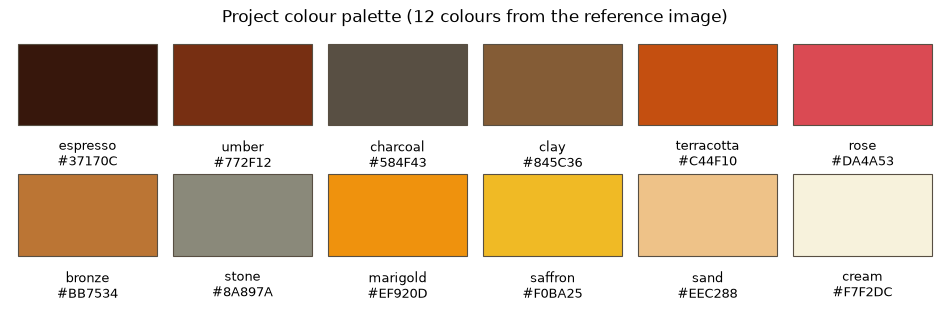

In [10]:
fig = style.palette_preview()
style.save_figure(fig, 2, "Project colour palette")
plt.show()

## 2.6 Raw Data Check

Copy `train.csv`, `test.csv`, `store.csv` and `sample_submission.csv` into `data/raw/`. In Colab, use the Files panel to upload them to that folder. The cell below confirms that all four files exist and that their row counts match the audit done earlier.

In [11]:
missing = [f"{name} ({path.name})" for name, path in config.RAW_FILES.items() if not path.exists()]
if missing:
    raise FileNotFoundError(f"Copy these files into {config.DATA_RAW} and re-run this cell: {missing}")

EXPECTED_ROWS = {"train.csv": 1_017_209, "test.csv": 41_088, "store.csv": 1_115, "sample_submission.csv": 41_088}

rows = []
for name, path in config.RAW_FILES.items():
    with open(path, "rb") as f:
        n_rows = sum(1 for _ in f) - 1                      # minus the header line
    rows.append({
        "file": path.name,
        "size_mb": round(path.stat().st_size / 1e6, 2),
        "rows": n_rows,
        "expected_rows": EXPECTED_ROWS[path.name],
        "matches": n_rows == EXPECTED_ROWS[path.name],
    })

raw_inventory = pd.DataFrame(rows)
style.show_table(raw_inventory, 2, "Raw data files")
logger.info(f"Raw data check: {int(raw_inventory['matches'].sum())} of {len(raw_inventory)} files match expected row counts.")

FileNotFoundError: Copy these files into /Users/kyra/Downloads/project 6/data/raw and re-run this cell: ['train (train.csv)', 'test (test.csv)', 'store (store.csv)', 'sample_submission (sample_submission.csv)']